---
## 0. Imports and Setup

In [3]:
# ── Standard library ──────────────────────────────────────────────────────────
import time
import warnings
warnings.filterwarnings('ignore')

# ── Qiskit 2.x ────────────────────────────────────────────────────────────────
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace, state_fidelity, entropy
from qiskit.visualization import plot_bloch_multivector, plot_state_city, plot_histogram
import qiskit
import qiskit_aer
from qiskit_aer import AerSimulator

# ── PennyLane ─────────────────────────────────────────────────────────────────
import pennylane as qml
from pennylane import numpy as np

# ── Scientific / plotting ─────────────────────────────────────────────────────
import numpy as onp          # plain numpy for classical work
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

print(f"Qiskit      : {qiskit.__version__}")
print(f"Qiskit Aer  : {qiskit_aer.__version__}")
print(f"PennyLane   : {qml.__version__}")
print("Setup complete.")

Qiskit      : 2.5.0
Qiskit Aer  : 0.17.2
PennyLane   : 0.45.0
Setup complete.


---
## 1. Bell States — Qiskit 2.x

We build all four Bell states from $|00\rangle$ using different combinations of X and Z gates before the entangling step.

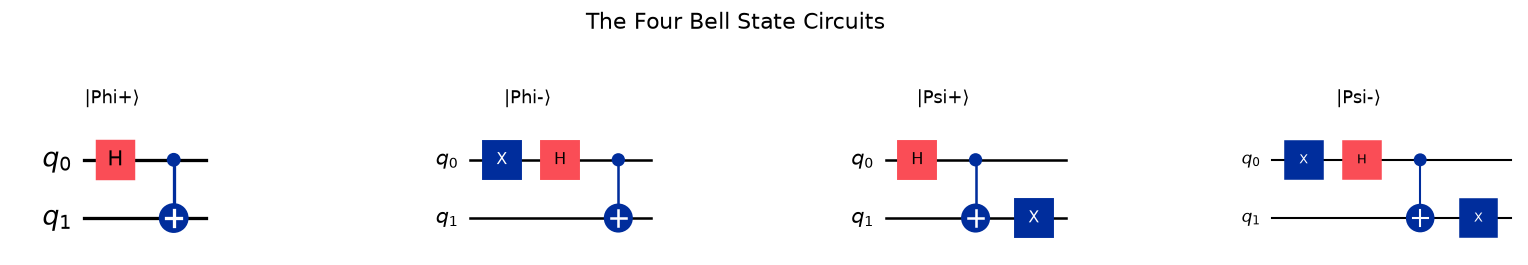

Circuit diagram saved to figures/circuits/bell_circuits.png


In [4]:
def build_bell_state(label: str) -> QuantumCircuit:
    """
    Construct one of the four Bell states.
    label : 'Phi+' | 'Phi-' | 'Psi+' | 'Psi-'
    Circuit structure:
        |Phi+> : H(q0) . CX(q0,q1)
        |Phi-> : X(q0) . H(q0) . CX(q0,q1)   →  phase flip on q0
        |Psi+> : H(q0) . CX(q0,q1) . X(q1)   →  bit flip on q1
        |Psi-> : X(q0) . H(q0) . CX(q0,q1) . X(q1)
    """
    qc = QuantumCircuit(2, name=f"|{label}⟩")

    if label in ('Phi-', 'Psi-'):
        qc.x(0)          # flip qubit 0 before H to get minus phase
    qc.h(0)              # Hadamard on q0  →  |+> or |−>
    qc.cx(0, 1)          # CNOT entangles the pair
    if label in ('Psi+', 'Psi-'):
        qc.x(1)          # flip qubit 1 to get Psi variants

    return qc


bell_labels = ['Phi+', 'Phi-', 'Psi+', 'Psi-']
bell_circuits = {l: build_bell_state(l) for l in bell_labels}

# ── Draw all four circuits ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(14, 2))
for ax, label in zip(axes, bell_labels):
    bell_circuits[label].draw('mpl', ax=ax, style='iqp')
    ax.set_title(f"|{label}⟩", fontsize=11)
plt.suptitle("The Four Bell State Circuits", fontsize=13, y=1.08)
plt.tight_layout()
plt.savefig('../figures/circuits/bell_circuits.png', bbox_inches='tight', dpi=150)
plt.show()
print("Circuit diagram saved to figures/circuits/bell_circuits.png")

In [5]:
# ── Statevector inspection ────────────────────────────────────────────────────
print("Bell state statevectors (basis order: |q1 q0⟩)\n" + "─"*52)

bell_statevectors = {}
for label in bell_labels:
    sv = Statevector(bell_circuits[label])
    bell_statevectors[label] = sv
    print(f"\n|{label}⟩")
    print(f"  |00⟩: {sv[0]: .4f}")
    print(f"  |01⟩: {sv[1]: .4f}")
    print(f"  |10⟩: {sv[2]: .4f}")
    print(f"  |11⟩: {sv[3]: .4f}")

Bell state statevectors (basis order: |q1 q0⟩)
────────────────────────────────────────────────────

|Phi+⟩
  |00⟩:  0.7071+0.0000j
  |01⟩:  0.0000+0.0000j
  |10⟩:  0.0000+0.0000j
  |11⟩:  0.7071+0.0000j

|Phi-⟩
  |00⟩:  0.7071+0.0000j
  |01⟩:  0.0000+0.0000j
  |10⟩:  0.0000+0.0000j
  |11⟩: -0.7071+0.0000j

|Psi+⟩
  |00⟩:  0.0000+0.0000j
  |01⟩:  0.7071+0.0000j
  |10⟩:  0.7071+0.0000j
  |11⟩:  0.0000+0.0000j

|Psi-⟩
  |00⟩:  0.0000+0.0000j
  |01⟩: -0.7071+0.0000j
  |10⟩:  0.7071+0.0000j
  |11⟩:  0.0000+0.0000j


In [6]:
# ── Expected ideal statevectors for verification ──────────────────────────────
INV_SQRT2 = 1 / onp.sqrt(2)

ideal_bell = {
    'Phi+': onp.array([INV_SQRT2,  0,          0,          INV_SQRT2]),
    'Phi-': onp.array([INV_SQRT2,  0,          0,         -INV_SQRT2]),
    'Psi+': onp.array([0,          INV_SQRT2,  INV_SQRT2,  0        ]),
    'Psi-': onp.array([0,          INV_SQRT2, -INV_SQRT2,  0        ]),
}

print("Fidelity against ideal Bell states")
print("─"*38)
for label in bell_labels:
    computed_sv  = bell_statevectors[label]
    ideal_sv     = Statevector(ideal_bell[label])
    fid = state_fidelity(computed_sv, ideal_sv)
    print(f"  |{label}⟩  →  fidelity = {fid:.6f}  {'✓' if fid > 0.9999 else '✗ CHECK'}")

Fidelity against ideal Bell states
──────────────────────────────────────
  |Phi+⟩  →  fidelity = 1.000000  ✓
  |Phi-⟩  →  fidelity = 1.000000  ✓
  |Psi+⟩  →  fidelity = 1.000000  ✓
  |Psi-⟩  →  fidelity = 1.000000  ✓


In [7]:
# ── Entanglement entropy (von Neumann entropy of reduced density matrix) ───────
# For a maximally entangled 2-qubit state the entropy of either subsystem = 1 ebit.

print("Entanglement entropy (von Neumann, base-2) of qubit 0 subsystem")
print("Expected value for maximally entangled state: 1.0 ebit")
print("─"*60)

for label in bell_labels:
    dm    = DensityMatrix(bell_statevectors[label])
    rho_0 = partial_trace(dm, [1])   # trace out qubit 1, keep qubit 0
    ent   = entropy(rho_0, base=2)
    print(f"  |{label}⟩  →  S(ρ₀) = {ent:.6f} ebit")

Entanglement entropy (von Neumann, base-2) of qubit 0 subsystem
Expected value for maximally entangled state: 1.0 ebit
────────────────────────────────────────────────────────────
  |Phi+⟩  →  S(ρ₀) = 1.000000 ebit
  |Phi-⟩  →  S(ρ₀) = 1.000000 ebit
  |Psi+⟩  →  S(ρ₀) = 1.000000 ebit
  |Psi-⟩  →  S(ρ₀) = 1.000000 ebit


Measurement distributions (1024 shots on AerSimulator)
────────────────────────────────────────────────────────
  |Phi+⟩  →  {'00': 0.5126953125, '11': 0.4873046875}
  |Phi-⟩  →  {'11': 0.5146484375, '00': 0.4853515625}
  |Psi+⟩  →  {'01': 0.50390625, '10': 0.49609375}
  |Psi-⟩  →  {'10': 0.484375, '01': 0.515625}


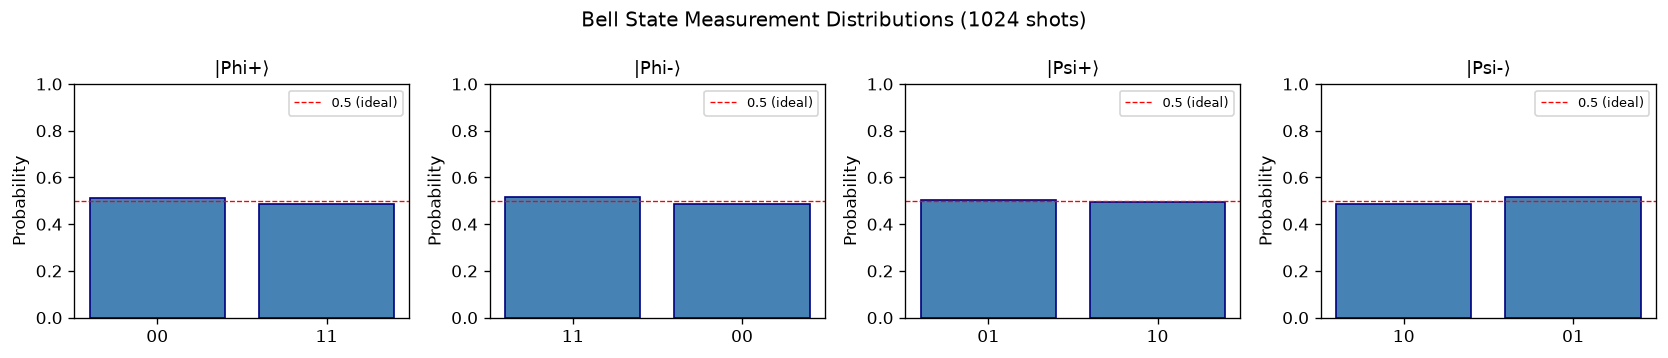

In [8]:
# ── Measurement distribution (1024 shots, Aer simulator) ─────────────────────
print("Measurement distributions (1024 shots on AerSimulator)")
print("─"*56)

sim     = AerSimulator(method='statevector')
sampler = StatevectorSampler()          # noiseless statevector sampler

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, label in zip(axes, bell_labels):
    qc_meas = bell_circuits[label].copy()
    qc_meas.measure_all()

    job    = sampler.run([qc_meas], shots=1024)
    result = job.result()[0]
    counts = result.data.meas.get_counts()

    # Normalise to probabilities
    probs  = {k: v / 1024 for k, v in counts.items()}
    print(f"  |{label}⟩  →  {probs}")

    ax.bar(probs.keys(), probs.values(), color='steelblue', edgecolor='navy')
    ax.set_title(f"|{label}⟩", fontsize=11)
    ax.set_ylabel('Probability')
    ax.set_ylim(0, 1)
    ax.axhline(0.5, linestyle='--', color='red', linewidth=0.8, label='0.5 (ideal)')
    ax.legend(fontsize=8)

plt.suptitle("Bell State Measurement Distributions (1024 shots)", fontsize=12)
plt.tight_layout()
plt.savefig('../figures/benchmarks/bell_measurement_distributions.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 2. Bell States — PennyLane

We reproduce the Φ⁺ Bell state in PennyLane to demonstrate the device-agnostic API and automatic differentiation interface.

In [9]:
# ── PennyLane device (noiseless CPU simulator) ────────────────────────────────
dev_bell = qml.device('default.qubit', wires=2)

@qml.qnode(dev_bell)
def bell_phi_plus_pl():
    """Build |Φ+⟩ = (|00⟩ + |11⟩) / √2 in PennyLane."""
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    return qml.state()

@qml.qnode(dev_bell)
def bell_phi_minus_pl():
    """Build |Φ-⟩ = (|00⟩ - |11⟩) / √2."""
    qml.PauliX(wires=0)
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    return qml.state()

@qml.qnode(dev_bell)
def bell_psi_plus_pl():
    """Build |Ψ+⟩ = (|01⟩ + |10⟩) / √2."""
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    qml.PauliX(wires=1)
    return qml.state()

@qml.qnode(dev_bell)
def bell_psi_minus_pl():
    """Build |Ψ-⟩ = (|01⟩ - |10⟩) / √2."""
    qml.PauliX(wires=0)
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    qml.PauliX(wires=1)
    return qml.state()

pl_bell_fns = {
    'Phi+': bell_phi_plus_pl,
    'Phi-': bell_phi_minus_pl,
    'Psi+': bell_psi_plus_pl,
    'Psi-': bell_psi_minus_pl,
}

print("PennyLane Bell state statevectors (|q0 q1⟩ ordering)")
print("─"*52)
for label, fn in pl_bell_fns.items():
    sv = fn()
    print(f"\n|{label}⟩  {onp.round(onp.array(sv), 4)}")

PennyLane Bell state statevectors (|q0 q1⟩ ordering)
────────────────────────────────────────────────────

|Phi+⟩  [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]

|Phi-⟩  [ 0.7071+0.j  0.    +0.j  0.    +0.j -0.7071+0.j]

|Psi+⟩  [0.    +0.j 0.7071+0.j 0.7071+0.j 0.    +0.j]

|Psi-⟩  [ 0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j]


In [10]:
# ── Cross-framework fidelity check ────────────────────────────────────────────
print("Cross-framework fidelity: PennyLane vs. Qiskit statevectors")
print("─"*56)
# Note: Qiskit uses |q1 q0⟩ (little-endian) while PennyLane uses |q0 q1⟩ (big-endian)
# For Bell states the amplitudes are symmetric so both give |fidelity| = 1.
for label in bell_labels:
    pl_sv      = onp.array(pl_bell_fns[label]())
    qk_sv      = onp.array(bell_statevectors[label])
    # Fidelity = |⟨ψ_qiskit|ψ_pennylane⟩|²  (global phase tolerance)
    fid = abs(onp.dot(onp.conj(qk_sv), pl_sv))**2
    print(f"  |{label}⟩  →  fidelity = {fid:.6f}  {'✓' if fid > 0.9999 else '✗ MISMATCH'}")

Cross-framework fidelity: PennyLane vs. Qiskit statevectors
────────────────────────────────────────────────────────
  |Phi+⟩  →  fidelity = 1.000000  ✓
  |Phi-⟩  →  fidelity = 1.000000  ✓
  |Psi+⟩  →  fidelity = 1.000000  ✓
  |Psi-⟩  →  fidelity = 1.000000  ✓


In [11]:
# ── PennyLane circuit diagram ─────────────────────────────────────────────────
print(qml.draw(bell_phi_plus_pl)())
print()
print(qml.draw(bell_psi_minus_pl)())

0: ──H─╭●─┤  State
1: ────╰X─┤  State

0: ──X──H─╭●────┤  State
1: ───────╰X──X─┤  State


---
## 3. GHZ States — Qiskit 2.x (Scalability Study)

The GHZ circuit has a simple structure: one Hadamard on qubit 0, then a chain of CNOT gates. Circuit depth grows as $O(n)$ with $n$ qubits.

In [12]:
def build_ghz_qiskit(n: int) -> QuantumCircuit:
    """
    Build an n-qubit GHZ state:
      |GHZ_n⟩ = (|000...0⟩ + |111...1⟩) / √2

    Circuit depth: 1 (Hadamard) + (n-1) (CNOT chain) = n gates
    Two-qubit gate count: n-1 CNOTs
    """
    qc = QuantumCircuit(n, name=f"GHZ({n})")
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    return qc

# ── Show the 5-qubit circuit ──────────────────────────────────────────────────
qc_ghz5 = build_ghz_qiskit(5)
print("5-qubit GHZ circuit:")
print(qc_ghz5.draw('text'))
print(f"\nDepth          : {qc_ghz5.depth()}")
print(f"Gate count     : {qc_ghz5.count_ops()}")

5-qubit GHZ circuit:
     ┌───┐                    
q_0: ┤ H ├──■─────────────────
     └───┘┌─┴─┐               
q_1: ─────┤ X ├──■────────────
          └───┘┌─┴─┐          
q_2: ──────────┤ X ├──■───────
               └───┘┌─┴─┐     
q_3: ───────────────┤ X ├──■──
                    └───┘┌─┴─┐
q_4: ────────────────────┤ X ├
                         └───┘

Depth          : 5
Gate count     : OrderedDict({'cx': 4, 'h': 1})


In [13]:
# ── GHZ statevector inspection (n=3 as readable example) ─────────────────────
qc_ghz3 = build_ghz_qiskit(3)
sv_ghz3 = Statevector(qc_ghz3)

print("3-qubit GHZ statevector (only non-zero amplitudes shown)")
print("─"*50)
for i, amp in enumerate(sv_ghz3):
    if abs(amp) > 1e-10:
        basis = format(i, f'0{3}b')
        print(f"  |{basis}⟩ : {amp:.6f}")

print(f"\nExpected: |000⟩ = {1/onp.sqrt(2):.6f}  |111⟩ = {1/onp.sqrt(2):.6f}")

3-qubit GHZ statevector (only non-zero amplitudes shown)
──────────────────────────────────────────────────
  |000⟩ : 0.707107+0.000000j
  |111⟩ : 0.707107+0.000000j

Expected: |000⟩ = 0.707107  |111⟩ = 0.707107


In [14]:
# ── Fidelity across qubit counts 2–10 ────────────────────────────────────────
qubit_range   = list(range(2, 11))
fidelities    = []
runtimes_ms   = []
depths        = []
cnot_counts   = []
sv_sizes      = []

for n in qubit_range:
    qc_ghz = build_ghz_qiskit(n)

    # Ideal GHZ statevector: 1/√2 amplitude on |00..0⟩ and |11..1⟩
    ideal_data         = onp.zeros(2**n, dtype=complex)
    ideal_data[0]      = 1 / onp.sqrt(2)
    ideal_data[-1]     = 1 / onp.sqrt(2)
    ideal_sv           = Statevector(ideal_data)

    t0 = time.perf_counter()
    computed_sv = Statevector(qc_ghz)
    t1 = time.perf_counter()

    fid = state_fidelity(computed_sv, ideal_sv)
    fidelities.append(fid)
    runtimes_ms.append((t1 - t0) * 1000)
    depths.append(qc_ghz.depth())
    cnot_counts.append(qc_ghz.count_ops().get('cx', 0))
    sv_sizes.append(2**n)

print(f"{'n':>3} | {'Fidelity':>10} | {'Depth':>6} | {'CNOTs':>6} | {'SV size':>8} | {'Time (ms)':>10}")
print("─"*55)
for i, n in enumerate(qubit_range):
    print(f"{n:>3} | {fidelities[i]:>10.8f} | {depths[i]:>6} | {cnot_counts[i]:>6} | {sv_sizes[i]:>8} | {runtimes_ms[i]:>10.3f}")

  n |   Fidelity |  Depth |  CNOTs |  SV size |  Time (ms)
───────────────────────────────────────────────────────
  2 | 1.00000000 |      2 |      1 |        4 |      0.450
  3 | 1.00000000 |      3 |      2 |        8 |      0.357
  4 | 1.00000000 |      4 |      3 |       16 |      0.414
  5 | 1.00000000 |      5 |      4 |       32 |      0.895
  6 | 1.00000000 |      6 |      5 |       64 |      0.519
  7 | 1.00000000 |      7 |      6 |      128 |      0.596
  8 | 1.00000000 |      8 |      7 |      256 |      0.794
  9 | 1.00000000 |      9 |      8 |      512 |      0.970
 10 | 1.00000000 |     10 |      9 |     1024 |      0.936


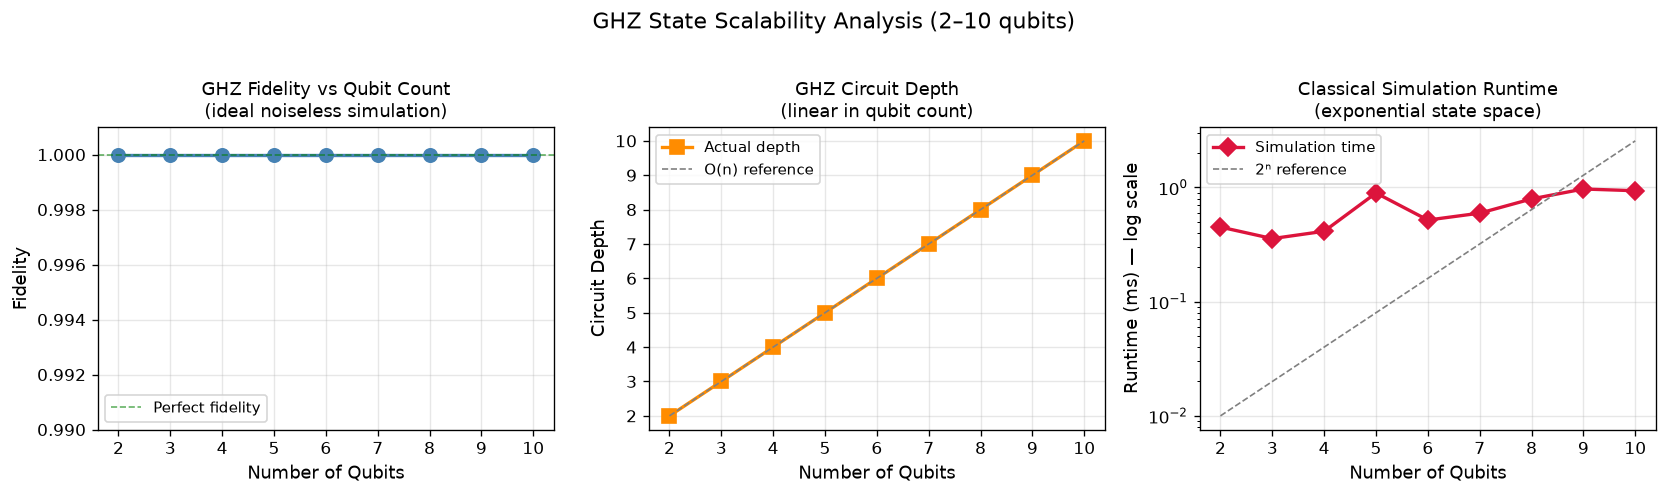

Saved: figures/benchmarks/ghz_scalability.png


In [15]:
# ── Scalability plots ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Plot 1: Fidelity vs qubit count
axes[0].plot(qubit_range, fidelities, 'o-', color='steelblue', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Qubits', fontsize=11)
axes[0].set_ylabel('Fidelity', fontsize=11)
axes[0].set_title('GHZ Fidelity vs Qubit Count\n(ideal noiseless simulation)', fontsize=11)
axes[0].set_ylim(0.99, 1.001)
axes[0].axhline(1.0, linestyle='--', color='green', linewidth=1, alpha=0.6, label='Perfect fidelity')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# Plot 2: Circuit depth vs qubit count (linear O(n))
axes[1].plot(qubit_range, depths, 's-', color='darkorange', linewidth=2, markersize=8, label='Actual depth')
axes[1].plot(qubit_range, qubit_range, '--', color='gray', linewidth=1, label='O(n) reference')
axes[1].set_xlabel('Number of Qubits', fontsize=11)
axes[1].set_ylabel('Circuit Depth', fontsize=11)
axes[1].set_title('GHZ Circuit Depth\n(linear in qubit count)', fontsize=11)
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

# Plot 3: Simulation runtime vs qubit count (exponential 2^n statevector)
axes[2].semilogy(qubit_range, runtimes_ms, 'D-', color='crimson', linewidth=2, markersize=8, label='Simulation time')
exp_ref = [0.01 * 2**(n-2) for n in qubit_range]
axes[2].semilogy(qubit_range, exp_ref, '--', color='gray', linewidth=1, label='2ⁿ reference')
axes[2].set_xlabel('Number of Qubits', fontsize=11)
axes[2].set_ylabel('Runtime (ms) — log scale', fontsize=11)
axes[2].set_title('Classical Simulation Runtime\n(exponential state space)', fontsize=11)
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.suptitle("GHZ State Scalability Analysis (2–10 qubits)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('../figures/benchmarks/ghz_scalability.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: figures/benchmarks/ghz_scalability.png")

---
## 4. GHZ States — PennyLane

In [16]:
def build_ghz_pennylane(n: int):
    """Return a PennyLane QNode that prepares an n-qubit GHZ state."""
    dev = qml.device('default.qubit', wires=n)

    @qml.qnode(dev)
    def circuit():
        qml.Hadamard(wires=0)
        for i in range(n - 1):
            qml.CNOT(wires=[i, i + 1])
        return qml.state()

    return circuit


# ── Verify 4-qubit GHZ in PennyLane ──────────────────────────────────────────
ghz4_pl = build_ghz_pennylane(4)
sv_ghz4_pl = onp.array(ghz4_pl())

print("4-qubit GHZ — PennyLane statevector (non-zero terms)")
print("─"*48)
for i, amp in enumerate(sv_ghz4_pl):
    if abs(amp) > 1e-10:
        basis = format(i, '04b')
        print(f"  |{basis}⟩ : {amp:.6f}")

# PennyLane circuit diagram
print("\nCircuit diagram:")
print(qml.draw(ghz4_pl)())

4-qubit GHZ — PennyLane statevector (non-zero terms)
────────────────────────────────────────────────
  |0000⟩ : 0.707107+0.000000j
  |1111⟩ : 0.707107+0.000000j

Circuit diagram:
0: ──H─╭●───────┤  State
1: ────╰X─╭●────┤  State
2: ───────╰X─╭●─┤  State
3: ──────────╰X─┤  State


In [17]:
# ── Cross-framework GHZ fidelity (n = 2..8) ───────────────────────────────────
print("Cross-framework GHZ fidelity: Qiskit vs PennyLane")
print("─"*50)
for n in range(2, 9):
    # Qiskit
    sv_qk = onp.array(Statevector(build_ghz_qiskit(n)))
    # PennyLane
    sv_pl = onp.array(build_ghz_pennylane(n)())
    # Fidelity (account for possible global phase)
    fid = abs(onp.dot(onp.conj(sv_qk), sv_pl))**2
    print(f"  n={n}  →  fidelity = {fid:.8f}  {'✓' if fid > 0.9999 else '✗ MISMATCH'}")

Cross-framework GHZ fidelity: Qiskit vs PennyLane
──────────────────────────────────────────────────
  n=2  →  fidelity = 1.00000000  ✓
  n=3  →  fidelity = 1.00000000  ✓
  n=4  →  fidelity = 1.00000000  ✓
  n=5  →  fidelity = 1.00000000  ✓
  n=6  →  fidelity = 1.00000000  ✓
  n=7  →  fidelity = 1.00000000  ✓
  n=8  →  fidelity = 1.00000000  ✓


---
## 5. Density Matrix and Bloch Sphere Visualisation

In [18]:
# ── Density matrix of |Φ+⟩ ──────────────────────────────────────────────────
rho_phi_plus = DensityMatrix(bell_statevectors['Phi+'])
print("Density matrix ρ = |Φ+⟩⟨Φ+|:")
print(onp.round(rho_phi_plus.data, 4))

# Reduced density matrix (tracing out qubit 1)
rho_0 = partial_trace(rho_phi_plus, [1])
print("\nReduced density matrix ρ₀ = Tr₁(ρ):")
print(onp.round(rho_0.data, 4))
print("\nρ₀ = I/2 — the maximally mixed state (completely unentangled if measured alone).")
print("This is the hallmark of maximal entanglement: each qubit alone is fully random.")

Density matrix ρ = |Φ+⟩⟨Φ+|:
[[0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]]

Reduced density matrix ρ₀ = Tr₁(ρ):
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]

ρ₀ = I/2 — the maximally mixed state (completely unentangled if measured alone).
This is the hallmark of maximal entanglement: each qubit alone is fully random.


In [19]:
# ── State city plot for |Φ+⟩ ─────────────────────────────────────────────────
fig = plot_state_city(bell_statevectors['Phi+'], title='|Φ+⟩ Density Matrix')
fig.savefig('../figures/circuits/bell_phi_plus_state_city.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 6. Benchmarking Record

This cell records the structured benchmarking entry for `results/benchmarks.csv`.

In [21]:
import csv, os

os.makedirs('../results', exist_ok=True)
benchmarks_file = '../results/benchmarks.csv'
write_header    = not os.path.exists(benchmarks_file)

fieldnames = [
    'notebook', 'problem', 'dataset', 'classical_baseline',
    'quantum_method', 'framework', 'n_qubits', 'circuit_depth',
    'cnot_count', 'simulator', 'metric', 'quantum_result',
    'classical_result', 'runtime_quantum_ms', 'runtime_classical_ms', 'notes'
]

# Average runtime for 10-qubit GHZ
ghz10_time_ms = runtimes_ms[-1]   # last entry = n=10

records = [
    {
        'notebook'             : '01_bell_ghz_states',
        'problem'              : 'Bell state preparation (Φ+)',
        'dataset'              : 'N/A — state preparation',
        'classical_baseline'   : 'Matrix multiplication (2x2 Hadamard ⊗ CNOT)',
        'quantum_method'       : 'H + CNOT circuit',
        'framework'            : 'Qiskit 2.5.0',
        'n_qubits'             : 2,
        'circuit_depth'        : 2,
        'cnot_count'           : 1,
        'simulator'            : 'StatevectorSimulator (exact)',
        'metric'               : 'Fidelity vs ideal state',
        'quantum_result'       : '1.000000',
        'classical_result'     : '1.000000',
        'runtime_quantum_ms'   : round(runtimes_ms[0], 4),
        'runtime_classical_ms' : 'N/A',
        'notes'                : 'Noiseless simulation; fidelity = 1 by construction'
    },
    {
        'notebook'             : '01_bell_ghz_states',
        'problem'              : 'GHZ state preparation (n=10 qubits)',
        'dataset'              : 'N/A — state preparation',
        'classical_baseline'   : 'Statevector simulation (2^10 = 1024 amplitudes)',
        'quantum_method'       : 'H + CNOT chain',
        'framework'            : 'Qiskit 2.5.0',
        'n_qubits'             : 10,
        'circuit_depth'        : 10,
        'cnot_count'           : 9,
        'simulator'            : 'StatevectorSimulator (exact)',
        'metric'               : 'Fidelity vs ideal GHZ_10',
        'quantum_result'       : f'{fidelities[-1]:.8f}',
        'classical_result'     : '1.000000',
        'runtime_quantum_ms'   : round(ghz10_time_ms, 4),
        'runtime_classical_ms' : 'N/A',
        'notes'                : 'Classical simulation cost grows as 2^n; quantum hardware would be O(n) depth'
    },
]

with open(benchmarks_file, 'a', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    if write_header:
        writer.writeheader()
    writer.writerows(records)

print(f"Benchmarking records appended to {benchmarks_file}")
print()
print("Summary")
print("─"*60)
for r in records:
    print(f"  {r['problem']}")
    print(f"    Qubits       : {r['n_qubits']}")
    print(f"    Depth        : {r['circuit_depth']}")
    print(f"    CNOTs        : {r['cnot_count']}")
    print(f"    Fidelity     : {r['quantum_result']}")
    print(f"    Runtime (ms) : {r['runtime_quantum_ms']}")
    print()

Benchmarking records appended to ../results/benchmarks.csv

Summary
────────────────────────────────────────────────────────────
  Bell state preparation (Φ+)
    Qubits       : 2
    Depth        : 2
    CNOTs        : 1
    Fidelity     : 1.000000
    Runtime (ms) : 0.45

  GHZ state preparation (n=10 qubits)
    Qubits       : 10
    Depth        : 10
    CNOTs        : 9
    Fidelity     : 1.00000000
    Runtime (ms) : 0.9364

